# 01 — Georgia 12-Lead ECG: Cohort, File/Header Integrity & Demographics

This notebook audits the **Georgia 12-Lead ECG Challenge Database** (Emory University / PhysioNet CinC 2020, `10,344` records across subfolders `g1`–`g11`) from a **data-cleaning and data-quality** standpoint:

1. **Filesystem & WFDB Header Integrity**: Auditing missing/corrupt `.hea`/`.mat` files, sampling rate (`500 Hz`), lead count (`12`), and **non-standard recording durations** (`n_samples != 5000`, which break naive PyTorch `DataLoader` batching!).
2. **Header Format Quirk Caught**: Georgia `.hea` files include a space after `#` (`# Age:`, `# Sex:`, `# Dx:`) unlike Chapman-Shaoxing (`#Age:`, `#Dx:`). Fixing `cinc_style_dataset.py` to match `#\s*` restored all `10,344` demographics and SNOMED-CT labels.
3. **Demographic Missingness & Outliers**: Auditing `# Age: NaN`, invalid/sentinel ages (`<= 0` or `> 100`), pediatric (`< 18`) records, sex coding consistency, and subfolder (`g1..g11`) balance.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import wfdb

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _candidate in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_candidate / "georgia_ecg" / "quality" / "error_labels.csv").exists():
        REPO_ROOT = _candidate
        break
else:
    raise FileNotFoundError(f"Could not locate georgia_ecg/quality/error_labels.csv from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from georgia_ecg import GeorgiaECGDataset

GEORGIA_DIR = REPO_ROOT / "georgia_ecg"
DATA_DIR = GEORGIA_DIR / "data"
LEADS = GeorgiaECGDataset.LEADS

df = pd.read_csv(GEORGIA_DIR / "quality" / "error_labels.csv", index_col="record_id")
df["snomed_codes"] = df["snomed_codes"].fillna("")
df["label_names"] = df["label_names"].fillna("")
df["error_tags"] = df["error_tags"].fillna("")
df["sex"] = df["sex"].fillna("")
print(f"Loaded {len(df):,} Georgia 12-Lead ECG records from error_labels.csv")

# 1. File & header integrity summary
print("=== File & Header Integrity Audit (N = {:,}) ===".format(len(df)))
print(f"  Missing / corrupt .hea or .mat : {int(df['err_file_missing_or_corrupt'].sum()):,}")
print(f"  Non-standard fs or lead order  : {int(df['err_hdr_nonstandard_fs_or_leads'].sum()):,}")
print(f"  Non-standard duration (!=10 s) : {int(df['err_hdr_nonstandard_duration'].sum()):,}")

missing_recs = df[df["err_file_missing_or_corrupt"] == 1][["record_path", "subfolder"]]
if len(missing_recs) > 0:
    print("\nMissing / unreadable records in RECORDS manifest:")
    display(missing_recs)

valid_df = df[df["err_file_missing_or_corrupt"] == 0].copy()
print("\nSampling rate counts:", valid_df["fs"].value_counts().to_dict())
print("Duration (seconds) distribution (top 10):")
print(valid_df["duration_s"].value_counts().head(10))

Loaded 10,344 Georgia 12-Lead ECG records from error_labels.csv
=== File & Header Integrity Audit (N = 10,344) ===
  Missing / corrupt .hea or .mat : 10
  Non-standard fs or lead order  : 0
  Non-standard duration (!=10 s) : 52

Missing / unreadable records in RECORDS manifest:


,record_path,subfolder
record_id,,
E01000,g1/E01000,g1
E02000,g2/E02000,g2
E03000,g3/E03000,g3
E04000,g4/E04000,g4
E05000,g5/E05000,g5
E06000,g6/E06000,g6
E07000,g7/E07000,g7
E08000,g8/E08000,g8
E09000,g9/E09000,g9



Sampling rate counts: {500: 10334}
Duration (seconds) distribution (top 10):
duration_s
10.0    10282
5.0        52
Name: count, dtype: int64


## 1.1 Demographic Audit (`age`, `sex`) & Subfolder (`g1..g11`) Balance

Let's inspect missing/sentinel ages (`NaN`, `<=0`, `>100`), pediatric records (`<18`), sex categories (`Male`/`Female`/`Unknown`), and check whether demographics or missing files cluster in specific `g1..g11` subfolders.

In [2]:
age_s = valid_df["age"]
print("=== Age Audit (among readable records) ===")
print(f"  Missing / NaN         : {int(valid_df['err_age_missing'].sum()):,} ({valid_df['err_age_missing'].mean()*100:.2f}%)")
print(f"  Invalid (<=0 or >100) : {int(valid_df['err_age_invalid_or_sentinel'].sum()):,}")
print(f"  Pediatric (0 < age<18): {int(valid_df['err_age_pediatric'].sum()):,}")
print(f"  Adult (18 <= age <=89): {int(((age_s >= 18) & (age_s <= 89)).sum()):,}")
print(f"  Elderly (90..100)     : {int(((age_s >= 90) & (age_s <= 100)).sum()):,}")
print(f"  Valid age range       : min={age_s.min()}, median={age_s.median()}, max={age_s.max()}")

print("\n=== Sex Audit ===")
print(valid_df["sex"].replace("", "<empty>").value_counts())

sub_order = [f"g{i}" for i in range(1, 12)]
sub_stats = df.groupby("subfolder").agg(
    n_records=("record_path", "size"),
    n_missing_file=("err_file_missing_or_corrupt", "sum"),
    n_non10s=("err_hdr_nonstandard_duration", "sum"),
    pct_age_missing=("err_age_missing", lambda s: round(s.mean() * 100, 2)),
    median_age=("age", "median"),
    pct_female=("sex", lambda s: round((s.str.lower() == "female").mean() * 100, 1)),
).reindex(sub_order)
display(sub_stats)

=== Age Audit (among readable records) ===
  Missing / NaN         : 77 (0.75%)
  Invalid (<=0 or >100) : 0
  Pediatric (0 < age<18): 3
  Adult (18 <= age <=89): 10,254
  Elderly (90..100)     : 0
  Valid age range       : min=14.0, median=62.0, max=89.0

=== Sex Audit ===
sex
Male      5548
Female    4786
Name: count, dtype: int64


,n_records,n_missing_file,n_non10s,pct_age_missing,median_age,pct_female
subfolder,,,,,,
g1,1000,1,10,2.40,63.0,43.5
g2,1000,1,1,0.30,60.0,49.1
g3,1000,1,0,0.00,61.0,42.9
g4,1000,1,0,0.00,62.0,47.0
g5,1000,1,0,0.00,63.0,48.8
g6,1000,1,0,0.00,64.0,45.1
g7,1000,1,0,0.00,65.0,50.4
g8,1000,1,0,0.70,61.0,49.9
g9,1000,1,16,2.70,59.0,42.9


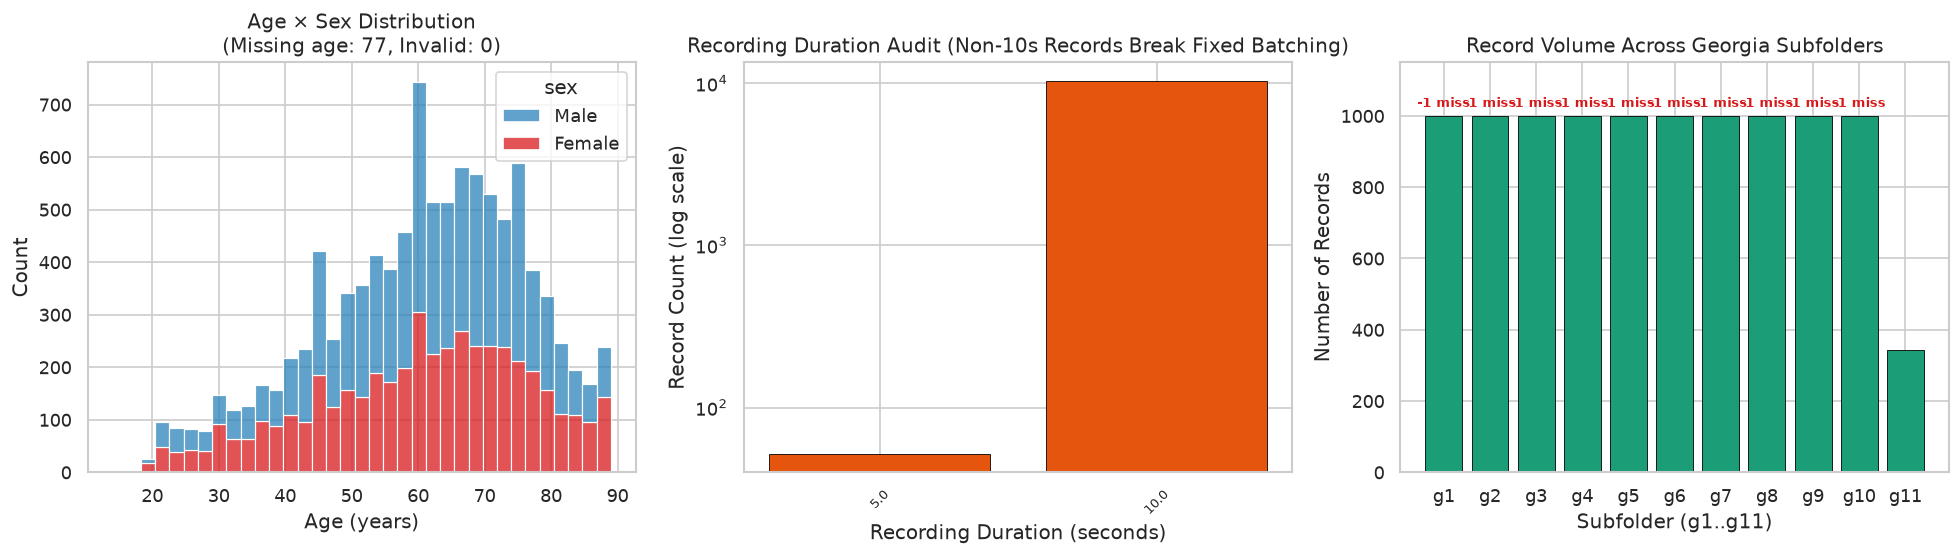

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

# Panel A: Age distribution by Sex
age_plot = valid_df[valid_df["age"].between(1, 100) & valid_df["sex"].isin(["Male", "Female"])]
sns.histplot(
    data=age_plot, x="age", hue="sex", bins=35, multiple="stack",
    palette={"Male": "#2b83ba", "Female": "#d7191c"}, ax=axes[0],
)
axes[0].set_xlabel("Age (years)")
axes[0].set_title(f"Age × Sex Distribution\n(Missing age: {int(valid_df['err_age_missing'].sum())}, Invalid: {int(valid_df['err_age_invalid_or_sentinel'].sum())})")

# Panel B: Recording duration distribution (log y-scale to reveal <10s outliers)
dur_vc = valid_df["duration_s"].round(1).value_counts().sort_index()
axes[1].bar(dur_vc.index.astype(str), dur_vc.values, color="#e6550d", edgecolor="black", lw=0.5)
axes[1].set_yscale("log")
axes[1].set_xlabel("Recording Duration (seconds)")
axes[1].set_ylabel("Record Count (log scale)")
axes[1].set_title("Recording Duration Audit (Non-10s Records Break Fixed Batching)")
axes[1].tick_params(axis="x", rotation=45, labelsize=8)

# Panel C: Subfolder g1..g11 record counts & non-10s / missing file highlights
axes[2].bar(sub_stats.index, sub_stats["n_records"], color="#1b9e77", edgecolor="black", lw=0.5)
axes[2].set_xlabel("Subfolder (g1..g11)")
axes[2].set_ylabel("Number of Records")
axes[2].set_title("Record Volume Across Georgia Subfolders")
for i, (cnt, nf) in enumerate(zip(sub_stats["n_records"], sub_stats["n_missing_file"])):
    if nf > 0:
        axes[2].text(i, cnt + 25, f"-{nf} miss", ha="center", fontsize=7.5, color="#d7191c", fontweight="bold")
axes[2].set_ylim(0, sub_stats["n_records"].max() * 1.15)

plt.tight_layout()
plt.show()